In [95]:
import pandas as pd
import numpy as np

In [96]:
path = "/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/processed dataset/final_df_(distance).parquet"

In [97]:
df = pd.read_parquet(path)

In [98]:
df.shape

(99418, 29)

In [99]:
final_features = [
    "total_price",
    "total_freight_value",
    "total_product_weight_g",
    "average_product_length_cm",
    "average_product_height_cm",
    "item_count",
    "max_payment_installments",
    "average_distance_km"
]

model_df = df.dropna(
    subset=final_features + ["is_delayed"]
).copy()

print(model_df.shape)

(95960, 29)


In [100]:
model_df[final_features + ["delivery_delay_days"]].corr()["delivery_delay_days"].sort_values()

average_distance_km         -0.074836
total_freight_value         -0.049373
item_count                  -0.031629
max_payment_installments    -0.031446
total_price                 -0.013052
average_product_height_cm   -0.002282
total_product_weight_g       0.002354
average_product_length_cm    0.009671
delivery_delay_days          1.000000
Name: delivery_delay_days, dtype: float64

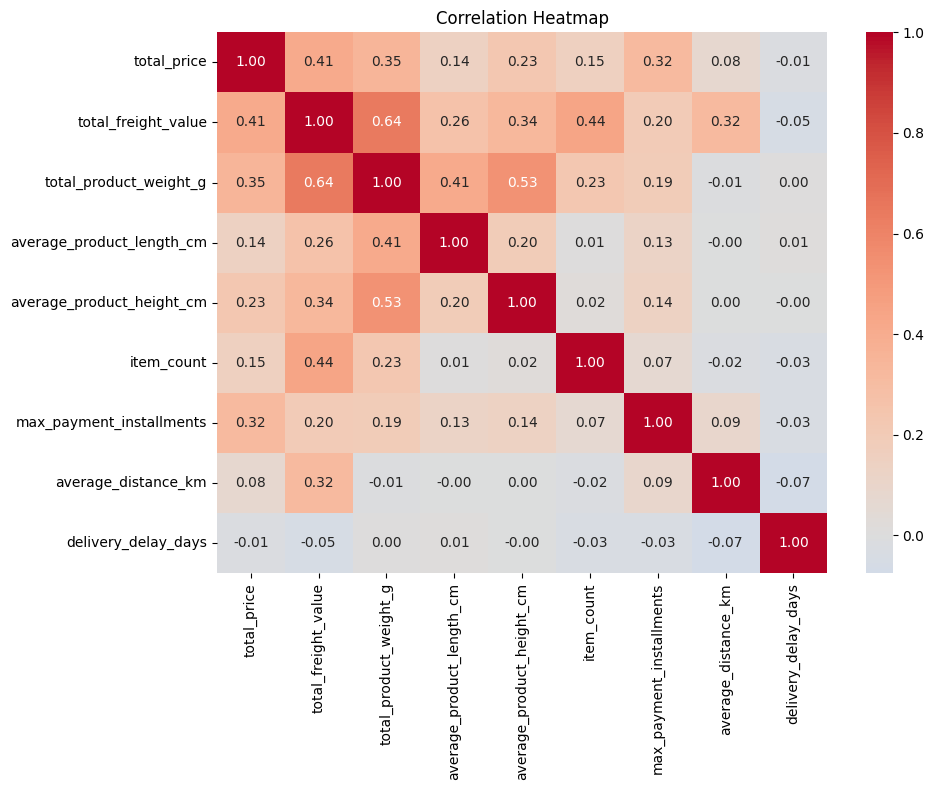

In [101]:
import seaborn as sns

import matplotlib.pyplot as plt

# Use only numeric modelling columns; exclude IDs, text, dates, and timedeltas
corr_columns = final_features + ["delivery_delay_days"]
corr = model_df[corr_columns].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [102]:
df.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'item_count', 'total_price', 'total_freight_value', 'n_unique_products',
       'n_unique_sellers', 'total_product_weight_g',
       'average_product_length_cm', 'average_product_height_cm',
       'average_product_width_cm', 'n_unique_categories',
       'n_unique_seller_city', 'n_unique_seller_state', 'total_payment_value',
       'max_payment_installments', 'n_unique_payment_types', 'customer_city',
       'customer_state', 'delivery_delay', 'delivery_delay_days', 'is_delayed',
       'average_distance_km'],
      dtype='object')

In [103]:
corr_matrix = df.corr(numeric_only=True).round(3)

corr_matrix["delivery_delay_days"].sort_values(ascending=False)

delivery_delay_days          1.000
is_delayed                   0.605
average_product_length_cm    0.010
total_product_weight_g       0.003
average_product_width_cm     0.000
average_product_height_cm   -0.002
n_unique_payment_types      -0.004
total_price                 -0.014
total_payment_value         -0.018
n_unique_categories         -0.028
max_payment_installments    -0.031
item_count                  -0.032
n_unique_products           -0.047
total_freight_value         -0.049
n_unique_seller_state       -0.050
n_unique_seller_city        -0.057
n_unique_sellers            -0.058
average_distance_km         -0.075
Name: delivery_delay_days, dtype: float64

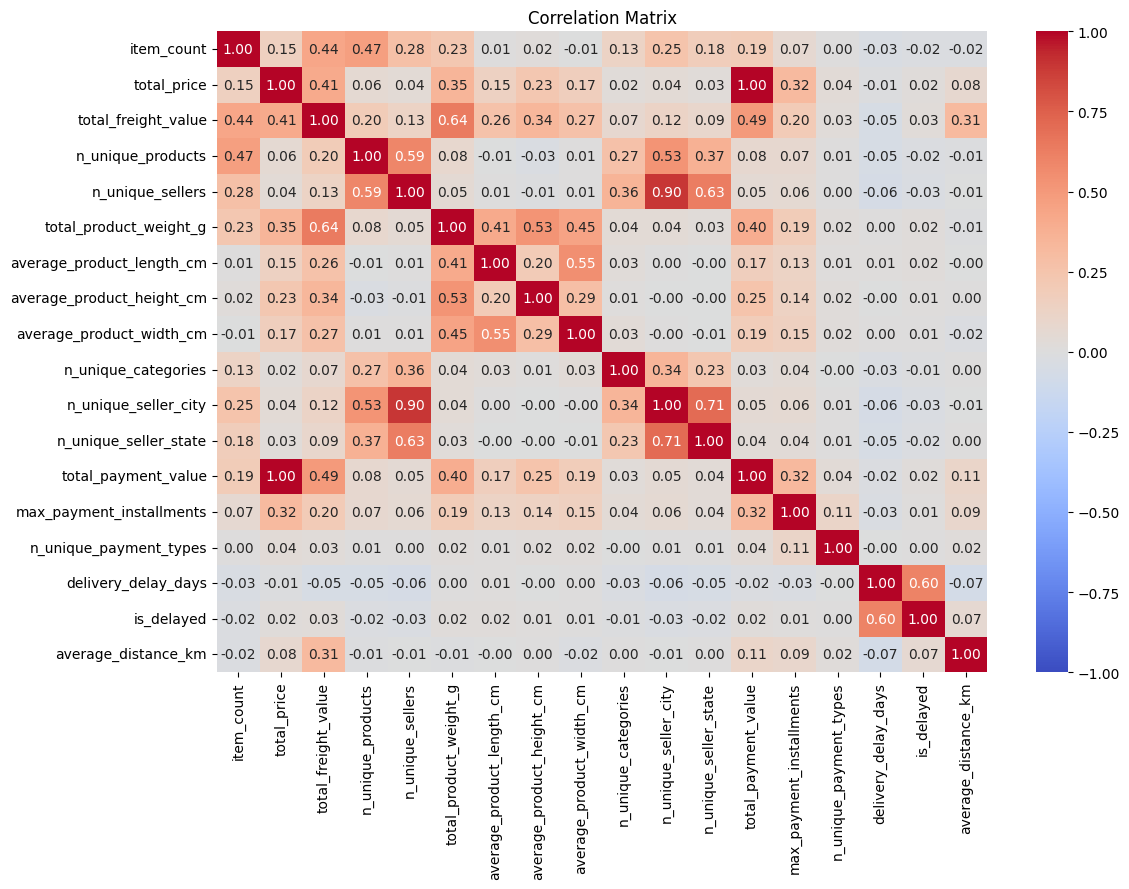

In [104]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [105]:
corr_matrix.corr().round(5)

,item_count,total_price,total_freight_value,n_unique_products,n_unique_sellers,total_product_weight_g,average_product_length_cm,average_product_height_cm,average_product_width_cm,n_unique_categories,n_unique_seller_city,n_unique_seller_state,total_payment_value,max_payment_installments,n_unique_payment_types,delivery_delay_days,is_delayed,average_distance_km
item_count,1.00000,0.05980,0.40803,0.64778,0.39506,0.10777,-0.22653,-0.15552,-0.24115,0.17819,0.36005,0.28332,0.09041,-0.09542,-0.19351,-0.31597,-0.32068,-0.14468
total_price,0.05980,1.00000,0.56486,-0.24108,-0.30978,0.48321,0.16251,0.35101,0.20101,-0.28222,-0.31172,-0.30182,0.99769,0.45087,-0.09993,-0.23910,-0.22555,0.04950
total_freight_value,0.40803,0.56486,1.00000,-0.07262,-0.22740,0.78509,0.31532,0.49635,0.33839,-0.24381,-0.24148,-0.25570,0.61962,0.21314,-0.21439,-0.40106,-0.34439,0.27266
n_unique_products,0.64778,-0.24108,-0.07262,1.00000,0.83361,-0.27511,-0.36979,-0.39157,-0.37745,0.48628,0.79647,0.68777,-0.23501,-0.20510,-0.19768,-0.33808,-0.34434,-0.21987
n_unique_sellers,0.39506,-0.30978,-0.22740,0.83361,1.00000,-0.36391,-0.37179,-0.39736,-0.38601,0.57907,0.99147,0.90116,-0.31314,-0.24226,-0.19605,-0.33452,-0.33889,-0.22593
total_product_weight_g,0.10777,0.48321,0.78509,-0.27511,-0.36391,1.00000,0.60991,0.76594,0.66360,-0.30317,-0.37050,-0.36897,0.52436,0.21741,-0.18201,-0.25306,-0.26855,-0.11034
average_product_length_cm,-0.22653,0.16251,0.31532,-0.36979,-0.37179,0.60991,1.00000,0.40128,0.82575,-0.26165,-0.37226,-0.35748,0.18045,0.11257,-0.12959,-0.14485,-0.17359,-0.13910
average_product_height_cm,-0.15552,0.35101,0.49635,-0.39157,-0.39736,0.76594,0.40128,1.00000,0.51244,-0.30023,-0.39232,-0.37239,0.37477,0.17363,-0.12344,-0.17124,-0.18528,-0.09491
average_product_width_cm,-0.24115,0.20101,0.33839,-0.37745,-0.38601,0.66360,0.82575,0.51244,1.00000,-0.27048,-0.38690,-0.37337,0.21910,0.15047,-0.12703,-0.16693,-0.19806,-0.16280
n_unique_categories,0.17819,-0.28222,-0.24381,0.48628,0.57907,-0.30317,-0.26165,-0.30023,-0.27048,1.00000,0.56560,0.47059,-0.28862,-0.22125,-0.18188,-0.26023,-0.27621,-0.18667


In [106]:
model_df[final_features].corr().round(3)

,total_price,total_freight_value,total_product_weight_g,average_product_length_cm,average_product_height_cm,item_count,max_payment_installments,average_distance_km
total_price,1.000,0.411,0.351,0.145,0.228,0.154,0.316,0.080
total_freight_value,0.411,1.000,0.641,0.258,0.335,0.439,0.201,0.315
total_product_weight_g,0.351,0.641,1.000,0.412,0.531,0.230,0.192,-0.010
average_product_length_cm,0.145,0.258,0.412,1.000,0.197,0.008,0.126,-0.004
average_product_height_cm,0.228,0.335,0.531,0.197,1.000,0.018,0.138,0.000
item_count,0.154,0.439,0.230,0.008,0.018,1.000,0.067,-0.016
max_payment_installments,0.316,0.201,0.192,0.126,0.138,0.067,1.000,0.091
average_distance_km,0.080,0.315,-0.010,-0.004,0.000,-0.016,0.091,1.000


# Missing injection

In [107]:
final_features = [
    "total_price",
    "total_freight_value",
    "total_product_weight_g",
    "average_product_length_cm",
    "average_product_height_cm",
    "item_count",
    "max_payment_installments",
    "average_distance_km"
]

In [108]:
experiment_columns = [
    "order_id",
    *final_features,
    "is_delayed"
]

In [109]:
model_df = df[experiment_columns].dropna().copy()

print(model_df.shape)
print(model_df.columns)

(95960, 10)
Index(['order_id', 'total_price', 'total_freight_value',
       'total_product_weight_g', 'average_product_length_cm',
       'average_product_height_cm', 'item_count', 'max_payment_installments',
       'average_distance_km', 'is_delayed'],
      dtype='object')


In [110]:
print(model_df.isna().sum())

order_id                     0
total_price                  0
total_freight_value          0
total_product_weight_g       0
average_product_length_cm    0
average_product_height_cm    0
item_count                   0
max_payment_installments     0
average_distance_km          0
is_delayed                   0
dtype: int64


In [111]:
target = "total_freight_value"

print("Target:", target)
print("Mean:", model_df[target].mean())
print("Missing:", model_df[target].isna().sum())

Target: total_freight_value
Mean: 22.777100666944563
Missing: 0


## MCAR injection

In [112]:
def inject_mcar(df, target, missing_rate, random_seed = 42):
    df_injected = df.copy()

    rng = np.random.default_rng(random_seed)

    n_missing = int(len(df_injected) * missing_rate)

    missing_indices = rng.choice(
        df_injected.index,
        size = n_missing,
        replace = False
    )

    df_injected.loc[missing_indices, target] = np.nan

    return df_injected

In [113]:
mcar_10 = inject_mcar(
    model_df,
    target = 'total_freight_value',
    missing_rate=0.1
)

mcar_30 = inject_mcar(
    model_df,
    target = 'total_freight_value',
    missing_rate=0.3
)

mcar_50 = inject_mcar(
    model_df,
    target = 'total_freight_value',
    missing_rate = 0.5
)

In [114]:
for name, data in {
    'MCAR 10%':mcar_10,
    'MCAR 30%':mcar_30,
    'MCAR 50%':mcar_50
}.items():
    print(
        name,
        '| missing: ',
        data['total_freight_value'].isna().sum(),
        '| rate: ',
        data['total_freight_value'].isna().mean()
    )

MCAR 10% | missing:  9596 | rate:  0.1
MCAR 30% | missing:  28788 | rate:  0.3
MCAR 50% | missing:  47980 | rate:  0.5


In [115]:
mcar_10.to_parquet("/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mcar_10.parquet", index=False)
mcar_30.to_parquet("/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mcar_30.parquet", index=False)
mcar_50.to_parquet("/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mcar_50.parquet", index=False)

In [116]:
mcar_10_mask = mcar_10["total_freight_value"].isna()
mcar_30_mask = mcar_30["total_freight_value"].isna()
mcar_50_mask = mcar_50["total_freight_value"].isna()

## MAR injection

For the simulated MAR mechanism, missingness in total_freight_value was generated as a function of the observed total_product_weight_g, an auxiliary variable strongly associated with freight value in the dataset.

In [117]:
#total_product_weight_g 越高 → 被选为 missing 的概率越高
def inject_mar(df,target, auxiliary, missing_rate, random_seed=42):
    df_injected = df.copy()

    rng = np.random.default_rng(random_seed)

    #high auxiliary vlaues --》 higher probability of being selected 
    weights = df_injected[auxiliary].rank(pct = True).to_numpy()
    weights = weights +0.01
    weights = weights/weights.sum()

    n_missing = int(len(df_injected)* missing_rate)

    missing_indices = rng.choice(
        df_injected.index,
        size = n_missing,
        replace = False,
        p = weights
    )

    df_injected.loc[missing_indices, target]=np.nan

    return df_injected

In [118]:
mar_10 = inject_mar(
    model_df,
    target="total_freight_value",
    auxiliary="total_product_weight_g",
    missing_rate=0.10,
    random_seed=42
)

In [119]:
mar_10.describe()

,total_price,total_freight_value,total_product_weight_g,average_product_length_cm,average_product_height_cm,item_count,max_payment_installments,average_distance_km
count,95960.000000,86364.000000,95960.000000,95960.000000,95960.000000,95960.000000,95960.000000,95960.000000
mean,137.069822,22.228041,2384.566267,30.077695,16.462999,1.142070,2.976626,600.829828
std,209.234391,20.758843,4767.831835,16.036169,13.250083,0.538865,2.736831,593.500298
min,0.850000,0.000000,0.000000,7.000000,2.000000,1.000000,0.000000,0.000000
25%,45.900000,13.710000,300.000000,18.000000,8.000000,1.000000,1.000000,187.752989
50%,86.000000,16.950000,750.000000,25.000000,13.000000,1.000000,2.000000,433.878565
75%,149.900000,23.500000,2050.000000,38.000000,20.000000,1.000000,4.000000,797.689662
max,13440.000000,1794.960000,184400.000000,105.000000,105.000000,21.000000,26.000000,8677.911622


In [120]:
mar_mask = mar_10["total_freight_value"].isna()

print("Missing group weight mean:",
      model_df.loc[mar_mask, "total_product_weight_g"].mean())

print("Observed group weight mean:",
      model_df.loc[~mar_mask, "total_product_weight_g"].mean())

Missing group weight mean: 3994.0051062942894
Observed group weight mean: 2205.7397295169285


In [121]:
mar_30 = inject_mar(
    model_df,
    target="total_freight_value",
    auxiliary="total_product_weight_g",
    missing_rate=0.30,
    random_seed=42
)

mar_50 = inject_mar(
    model_df,
    target="total_freight_value",
    auxiliary="total_product_weight_g",
    missing_rate=0.50,
    random_seed=42
)

In [122]:
print("MAR 30%:", mar_30["total_freight_value"].isna().mean())
print("MAR 50%:", mar_50["total_freight_value"].isna().mean())

MAR 30%: 0.3
MAR 50%: 0.5


In [123]:
mar_30_mask = mar_30["total_freight_value"].isna()
mar_50_mask = mar_50["total_freight_value"].isna()

print("MAR 30%")
print("Missing group:", model_df.loc[mar_30_mask, "total_product_weight_g"].mean())
print("Observed group:", model_df.loc[~mar_30_mask, "total_product_weight_g"].mean())

print("\nMAR 50%")
print("Missing group:", model_df.loc[mar_50_mask, "total_product_weight_g"].mean())
print("Observed group:", model_df.loc[~mar_50_mask, "total_product_weight_g"].mean())

MAR 30%
Missing group: 3721.4135751007366
Observed group: 1811.6317066634908

MAR 50%
Missing group: 3452.643268028345
Observed group: 1316.4892663609837


MAR validation by missingness rate

Mean product weight for records with missing versus observed total_freight_value.

In [124]:
# Save MAR
mar_10.to_parquet("/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mar_10.parquet", index=False)
mar_30.to_parquet("/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mar_30.parquet", index=False)
mar_50.to_parquet("/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mar_50.parquet", index=False)

In [125]:
import os

for file in [
    "/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mcar_10.parquet",
    "/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mcar_30.parquet",
    "/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mcar_50.parquet",
    "/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mar_10.parquet",
    "/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mar_30.parquet",
    "/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mar_50.parquet"
]:
    print(file, os.path.exists(file))

/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mcar_10.parquet True
/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mcar_30.parquet True
/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mcar_50.parquet True
/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mar_10.parquet True
/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mar_30.parquet True
/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mar_50.parquet True


## MNAR injection

In [126]:
def inject_mnar(df, target, missing_rate, random_seed=42):
    df_injected = df.copy()

    rng = np.random.default_rng(random_seed)

    weights = df_injected[target].rank(pct=True).to_numpy()
    weights = weights + 0.01
    weights = weights / weights.sum()

    n_missing = int(len(df_injected) * missing_rate)

    missing_indices = rng.choice(
        df_injected.index,
        size=n_missing,
        replace=False,
        p=weights
    )

    df_injected.loc[missing_indices, target] = np.nan

    return df_injected

In [127]:
mnar_10 = inject_mnar(
    model_df,
    target="total_freight_value",
    missing_rate=0.10,
    random_seed=42
)

In [128]:
mnar_mask = mnar_10["total_freight_value"].isna()

print("Missing group original mean:",
      model_df.loc[mnar_mask, "total_freight_value"].mean())

print("Observed group mean:",
      model_df.loc[~mnar_mask, "total_freight_value"].mean())

Missing group original mean: 30.94981137974156
Observed group mean: 21.869021698856002


In [129]:
mnar_30 = inject_mnar(
    model_df,
    target="total_freight_value",
    missing_rate=0.30,
    random_seed=42
)

mnar_50 = inject_mnar(
    model_df,
    target="total_freight_value",
    missing_rate=0.50,
    random_seed=42
)

In [130]:
mnar_30_mask = mnar_30["total_freight_value"].isna()
mnar_50_mask = mnar_50["total_freight_value"].isna()

print("MNAR 30%")
print("Missing group:",
      model_df.loc[mnar_30_mask, "total_freight_value"].mean())
print("Observed group:",
      model_df.loc[~mnar_30_mask, "total_freight_value"].mean())

print("\nMNAR 50%")
print("Missing group:",
      model_df.loc[mnar_50_mask, "total_freight_value"].mean())
print("Observed group:",
      model_df.loc[~mnar_50_mask, "total_freight_value"].mean())

MNAR 30%
Missing group: 29.46065270251494
Observed group: 19.91272122312868

MNAR 50%
Missing group: 28.125446852855355
Observed group: 17.428754481033764


In [131]:
mnar_10.to_parquet("/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mnar_10.parquet", index=False)
mnar_30.to_parquet("/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mnar_30.parquet", index=False)
mnar_50.to_parquet("/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mnar_50.parquet", index=False)

# Imputation

## Imputation for MCAR

In [132]:
# Save missing masks for later evaluation
mcar_10_mask = mcar_10["total_freight_value"].isna()
mcar_30_mask = mcar_30["total_freight_value"].isna()
mcar_50_mask = mcar_50["total_freight_value"].isna()

mar_10_mask = mar_10["total_freight_value"].isna()
mar_30_mask = mar_30["total_freight_value"].isna()
mar_50_mask = mar_50["total_freight_value"].isna()

mnar_10_mask = mnar_10["total_freight_value"].isna()
mnar_30_mask = mnar_30["total_freight_value"].isna()
mnar_50_mask = mnar_50["total_freight_value"].isna()

In [133]:
mcar_10_mask.sum()

np.int64(9596)

### Mean Imputation

In [134]:
from sklearn.impute import SimpleImputer

# Copy the injected dataset
mcar_10_mean = mcar_10.copy()

# Create imputer
mean_imputer = SimpleImputer(strategy="mean")

# Impute total_freight_value
mcar_10_mean[["total_freight_value"]] = mean_imputer.fit_transform(
    mcar_10_mean[["total_freight_value"]]
)

In [135]:
mcar_10_mean["total_freight_value"].isna().sum()

np.int64(0)

In [136]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

original_values = model_df.loc[
    mcar_10_mask, "total_freight_value"
]

imputed_values = mcar_10_mean.loc[
    mcar_10_mask, "total_freight_value"
]

mae = mean_absolute_error(original_values, imputed_values)

rmse = np.sqrt(
    mean_squared_error(original_values, imputed_values)
)

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 11.383584345176551
RMSE: 20.51516583094975


#### mae,rmse function

In [137]:
def evaluate_imputation(original_df, imputed_df, mask, target):
    original_values = original_df.loc[mask, target]
    imputed_values = imputed_df.loc[mask, target]

    mae = mean_absolute_error(original_values, imputed_values)
    rmse = np.sqrt(
        mean_squared_error(original_values, imputed_values)
    )

    return mae, rmse

In [138]:
# MCAR 30% - Mean
mcar_30_mean = mcar_30.copy()

mcar_30_mean[["total_freight_value"]] = mean_imputer.fit_transform(
    mcar_30_mean[["total_freight_value"]]
)

mcar_30_mean_mae, mcar_30_mean_rmse = evaluate_imputation(
    model_df,
    mcar_30_mean,
    mcar_30_mask,
    "total_freight_value"
)

print("MCAR 30% Mean")
print("MAE:", mcar_30_mean_mae)
print("RMSE:", mcar_30_mean_rmse)

MCAR 30% Mean
MAE: 11.333445942593821
RMSE: 20.212462339269223


In [139]:
mcar_50_mean = mcar_50.copy()

mcar_50_mean[["total_freight_value"]] = mean_imputer.fit_transform(
    mcar_50_mean[["total_freight_value"]]
)

mcar_50_mean_mae, mcar_50_mean_rmse = evaluate_imputation(
    model_df,
    mcar_50_mean,
    mcar_50_mask,
    "total_freight_value"
)

print("MCAR 50% Mean")
print("MAE:", mcar_50_mean_mae)
print("RMSE:", mcar_50_mean_rmse)

MCAR 50% Mean
MAE: 11.374564118855275
RMSE: 20.800505593251685


### Median imputation

In [140]:
from sklearn.impute import SimpleImputer

median_imputer = SimpleImputer(strategy="median")

mcar_10_median = mcar_10.copy()

mcar_10_median[["total_freight_value"]] = median_imputer.fit_transform(
    mcar_10_median[["total_freight_value"]]
)

mcar_10_median_mae, mcar_10_median_rmse = evaluate_imputation(
    model_df,
    mcar_10_median,
    mcar_10_mask,
    "total_freight_value"
)

print("MCAR 10% Median")
print("MAE:", mcar_10_median_mae)
print("RMSE:", mcar_10_median_rmse)

MCAR 10% Median
MAE: 9.76814089203835
RMSE: 21.208753115446537


In [141]:
mcar_30_median = mcar_30.copy()

mcar_30_median[["total_freight_value"]] = median_imputer.fit_transform(
    mcar_30_median[["total_freight_value"]]
)

mcar_30_median_mae, mcar_30_median_rmse = evaluate_imputation(
    model_df,
    mcar_30_median,
    mcar_30_mask,
    "total_freight_value"
)

print("MCAR 30% Median")
print("MAE:", mcar_30_median_mae)
print("RMSE:", mcar_30_median_rmse)

MCAR 30% Median
MAE: 9.766736487425314
RMSE: 20.935556348702722


In [142]:
mcar_50_median = mcar_50.copy()

mcar_50_median[["total_freight_value"]] = median_imputer.fit_transform(
    mcar_50_median[["total_freight_value"]]
)

mcar_50_median_mae, mcar_50_median_rmse = evaluate_imputation(
    model_df,
    mcar_50_median,
    mcar_50_mask,
    "total_freight_value"
)

print("MCAR 50% Median")
print("MAE:", mcar_50_median_mae)
print("RMSE:", mcar_50_median_rmse)

MCAR 50% Median
MAE: 9.763730304293455
RMSE: 21.492491789705408


### KNN imputation

In [143]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

knn_features = [
    "total_price",
    "total_freight_value",
    "total_product_weight_g",
    "average_product_length_cm",
    "average_product_height_cm",
    "item_count",
    "max_payment_installments",
    "average_distance_km"
]

In [144]:
scaler = StandardScaler()

X_mcar_10 = mcar_10[knn_features].copy()

X_scaled = scaler.fit_transform(X_mcar_10)

In [145]:
knn_imputer = KNNImputer(
    n_neighbors=5,
    weights="uniform"
)

X_imputed_scaled = knn_imputer.fit_transform(X_scaled)

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: in

In [146]:
X_imputed_scaled = pd.DataFrame(
    X_imputed_scaled,
    columns=knn_features,
    index=mcar_10.index
)

In [147]:
mcar_10_knn = mcar_10.copy()

mcar_10_knn["total_freight_value"] = (
    X_imputed_scaled["total_freight_value"]
)

In [148]:
mcar_10_knn["total_freight_value"].isna().sum()

np.int64(0)

In [149]:
original_values = model_df.loc[
    mcar_10_mask, "total_freight_value"
]

imputed_values = mcar_10_knn.loc[
    mcar_10_mask, "total_freight_value"
]

mcar_10_knn_mae = mean_absolute_error(
    original_values,
    imputed_values
)

mcar_10_knn_rmse = np.sqrt(
    mean_squared_error(
        original_values,
        imputed_values
    )
)

print("MCAR 10% KNN")
print("MAE:", mcar_10_knn_mae)
print("RMSE:", mcar_10_knn_rmse)

MCAR 10% KNN
MAE: 22.600255357698423
RMSE: 30.085326164507403


In [150]:
#KNN function
def knn_impute(df, features, n_neighbors=5):
    df_imputed = df.copy()

    # Select features used for KNN
    X = df_imputed[features].copy()

    # Standardize features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # KNN imputation
    imputer = KNNImputer(
        n_neighbors=n_neighbors,
        weights="uniform"
    )

    X_imputed_scaled = imputer.fit_transform(X_scaled)

    # Convert back to DataFrame
    X_imputed_scaled = pd.DataFrame(
        X_imputed_scaled,
        columns=features,
        index=df.index
    )

    # Put imputed values back
    df_imputed[features] = X_imputed_scaled

    return df_imputed

In [151]:
knn_results = []

for rate, data, mask in [
    (0.10, mcar_10, mcar_10_mask),
    (0.30, mcar_30, mcar_30_mask),
    (0.50, mcar_50, mcar_50_mask)
]:
    imputed = knn_impute(data, knn_features)

    mae, rmse = evaluate_imputation(
        model_df,
        imputed,
        mask,
        "total_freight_value"
    )

    knn_results.append({
        "mechanism": "MCAR",
        "missing_rate": rate,
        "method": "KNN",
        "MAE": mae,
        "RMSE": rmse
    })

knn_results

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: in

[{'mechanism': 'MCAR',
  'missing_rate': 0.1,
  'method': 'KNN',
  'MAE': 22.600255357698423,
  'RMSE': np.float64(30.085326164507403)},
 {'mechanism': 'MCAR',
  'missing_rate': 0.3,
  'method': 'KNN',
  'MAE': 22.686304071831422,
  'RMSE': np.float64(29.969639895770058)},
 {'mechanism': 'MCAR',
  'missing_rate': 0.5,
  'method': 'KNN',
  'MAE': 22.696945093541128,
  'RMSE': np.float64(30.370468704489653)}]

## MCAR redults

In [153]:
'''def add_result(results, mechanism, missing_rate, method,
               original_df, imputed_df, mask, target):

    mae, rmse = evaluate_imputation(
        original_df,
        imputed_df,
        mask,
        target
    )

    results.append({
        "mechanism": mechanism,
        "missing_rate": missing_rate,
        "method": method,
        "MAE": mae,
        "RMSE": rmse
    })'''

'def add_result(results, mechanism, missing_rate, method,\n               original_df, imputed_df, mask, target):\n\n    mae, rmse = evaluate_imputation(\n        original_df,\n        imputed_df,\n        mask,\n        target\n    )\n\n    results.append({\n        "mechanism": mechanism,\n        "missing_rate": missing_rate,\n        "method": method,\n        "MAE": mae,\n        "RMSE": rmse\n    })'

## Imputation for MAR

### Mean imputation for MAR

In [ ]:
def mean_impute(df, target):
    df_imputed = df.copy()

    mean_value = df_imputed[target].mean()
    df_imputed[target] = df_imputed[target].filna(mean_value)

    return df_imputed

In [155]:
mar_data = {
    0.10: (mar_10, mar_10_mask),
    0.30: (mar_30, mar_30_mask),
    0.50: (mar_50, mar_50_mask)
}

In [156]:
mar_mean_results = []

for rate, (mar_df, mar_mask) in mar_data.items():
    
    imputed_df = mean_impute(
        mar_df,
        "total_freight_value"
    )
    
    mae, rmse = evaluate_imputation(
        model_df,
        imputed_df,
        mar_mask,
        "total_freight_value"
    )
    
    mar_mean_results.append({
        "mechanism": "MAR",
        "missing_rate": rate,
        "method": "Mean",
        "MAE": mae,
        "RMSE": rmse
    })

mar_mean_results

[{'mechanism': 'MAR',
  'missing_rate': 0.1,
  'method': 'Mean',
  'MAE': 13.66339126079176,
  'RMSE': np.float64(27.970665061014415)},
 {'mechanism': 'MAR',
  'missing_rate': 0.3,
  'method': 'Mean',
  'MAE': 12.836970902203648,
  'RMSE': np.float64(27.846714093179475)},
 {'mechanism': 'MAR',
  'missing_rate': 0.5,
  'method': 'Mean',
  'MAE': 12.100830758508694,
  'RMSE': np.float64(26.597817665838484)}]

### Median Imputation for MAR

In [157]:
def median_impute(df, target):
    df_imputed = df.copy()
    
    median_value = df_imputed[target].median()
    df_imputed[target] = df_imputed[target].fillna(median_value)
    
    return df_imputed

In [158]:
mar_median_results = []

for rate, (mar_df, mar_mask) in mar_data.items():
    
    imputed_df = median_impute(
        mar_df,
        "total_freight_value"
    )
    
    mae, rmse = evaluate_imputation(
        model_df,
        imputed_df,
        mar_mask,
        "total_freight_value"
    )
    
    mar_median_results.append({
        "mechanism": "MAR",
        "missing_rate": rate,
        "method": "Median",
        "MAE": mae,
        "RMSE": rmse
    })

mar_median_results

[{'mechanism': 'MAR',
  'missing_rate': 0.1,
  'method': 'Median',
  'MAE': 13.564738432680285,
  'RMSE': np.float64(29.464809066978198)},
 {'mechanism': 'MAR',
  'missing_rate': 0.3,
  'method': 'Median',
  'MAE': 12.94999096845908,
  'RMSE': np.float64(29.140019705856254)},
 {'mechanism': 'MAR',
  'missing_rate': 0.5,
  'method': 'Median',
  'MAE': 12.472031471446435,
  'RMSE': np.float64(27.708359648529452)}]

### KNN imputation for MAR

In [159]:
mar_knn_results = []

for rate, (mar_df, mar_mask) in mar_data.items():
    
    imputed_df = knn_impute(
        mar_df,
        knn_features
    )
    
    mae, rmse = evaluate_imputation(
        model_df,
        imputed_df,
        mar_mask,
        "total_freight_value"
    )
    
    mar_knn_results.append({
        "mechanism": "MAR",
        "missing_rate": rate,
        "method": "KNN",
        "MAE": mae,
        "RMSE": rmse
    })

mar_knn_results

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: in

[{'mechanism': 'MAR',
  'missing_rate': 0.1,
  'method': 'KNN',
  'MAE': 27.505848131408513,
  'RMSE': np.float64(38.266211229006046)},
 {'mechanism': 'MAR',
  'missing_rate': 0.3,
  'method': 'KNN',
  'MAE': 26.589511070248808,
  'RMSE': np.float64(37.474737053604926)},
 {'mechanism': 'MAR',
  'missing_rate': 0.5,
  'method': 'KNN',
  'MAE': 25.721053501181338,
  'RMSE': np.float64(35.78669624968095)}]

## MAR results

In [160]:
results.extend(mar_mean_results)
results.extend(mar_median_results)
results.extend(mar_knn_results)

results_df = pd.DataFrame(results)

results_df

,mechanism,missing_rate,method,MAE,RMSE
0,MCAR,0.1,Mean,11.383584,20.515166
1,MCAR,0.3,Mean,11.333446,20.212462
2,MCAR,0.5,Mean,11.374564,20.800506
3,MCAR,0.1,Median,9.768141,21.208753
4,MCAR,0.3,Median,9.766736,20.935556
5,MCAR,0.5,Median,9.763730,21.492492
6,MCAR,0.1,KNN,22.600255,30.085326
7,MCAR,0.3,KNN,22.686304,29.969640
8,MCAR,0.5,KNN,22.696945,30.370469
9,MAR,0.1,Mean,13.663391,27.970665


In [163]:
results_df.shape

(18, 5)

## Imputation for MNAR

### Mean imputation for MNAR

In [182]:
def median_impute(df, target):
    df_imputed = df.copy()
    
    median_value = df_imputed[target].median()
    df_imputed[target] = df_imputed[target].fillna(median_value)
    
    return df_imputed

In [183]:
mnar_data = {
    0.10: (mnar_10, mnar_10_mask),
    0.30: (mnar_30, mnar_30_mask),
    0.50: (mnar_50, mnar_50_mask)
}

In [184]:
mnar_mean_results = []

for rate, (mnar_df, mnar_mask) in mnar_data.items():
    
    imputed_df = mean_impute(
        mnar_df,
        "total_freight_value"
    )
    
    mae, rmse = evaluate_imputation(
        model_df,
        imputed_df,
        mnar_mask,
        "total_freight_value"
    )
    
    mnar_mean_results.append({
        "mechanism": "MNAR",
        "missing_rate": rate,
        "method": "Mean",
        "MAE": mae,
        "RMSE": rmse
    })

mnar_mean_results

[{'mechanism': 'MNAR',
  'missing_rate': 0.1,
  'method': 'Mean',
  'MAE': 14.125427329968339,
  'RMSE': np.float64(35.07311241512299)},
 {'mechanism': 'MNAR',
  'missing_rate': 0.3,
  'method': 'Mean',
  'MAE': 13.101698451860367,
  'RMSE': np.float64(30.05379782507587)},
 {'mechanism': 'MNAR',
  'missing_rate': 0.5,
  'method': 'Mean',
  'MAE': 12.55665533401874,
  'RMSE': np.float64(27.969749208317154)}]

In [187]:
results = [
    item
    for item in results
    if isinstance(item, dict)
]

results_df = pd.DataFrame(results)

results_df = results_df.drop_duplicates().sort_values(
    ["mechanism", "missing_rate", "method"]
).reset_index(drop=True)

results_df

,mechanism,missing_rate,method,MAE,RMSE
0,MAR,0.1,KNN,27.505848,38.266211
1,MAR,0.1,Mean,13.663391,27.970665
2,MAR,0.1,Median,13.564738,29.464809
3,MAR,0.3,KNN,26.589511,37.474737
4,MAR,0.3,Mean,12.836971,27.846714
5,MAR,0.3,Median,12.949991,29.140020
6,MAR,0.5,KNN,25.721054,35.786696
7,MAR,0.5,Mean,12.100831,26.597818
8,MAR,0.5,Median,12.472031,27.708360
9,MCAR,0.1,KNN,22.600255,30.085326


### Median imputation for MNAR

In [ ]:
mnar_median_results = []

for rate, (mnar_df, mnar_mask) in mnar_data.items():
    
    imputed_df = median_impute(
        mnar_df,
        "total_freight_value"
    )
    
    mae, rmse = evaluate_imputation(
        model_df,
        imputed_df,
        mnar_mask,
        "total_freight_value"
    )
    
    mnar_median_results.append({
        "mechanism": "MNAR",
        "missing_rate": rate,
        "method": "Median",
        "MAE": mae,
        "RMSE": rmse
    })

mnar_median_results

[{'mechanism': 'MNAR',
  'missing_rate': 0.1,
  'method': 'Median',
  'MAE': 15.280772196748647,
  'RMSE': np.float64(36.71733557279498)},
 {'mechanism': 'MNAR',
  'missing_rate': 0.3,
  'method': 'Median',
  'MAE': 14.503481659024596,
  'RMSE': np.float64(31.619229159649194)},
 {'mechanism': 'MNAR',
  'missing_rate': 0.5,
  'method': 'Median',
  'MAE': 13.720313047102959,
  'RMSE': np.float64(28.940454536778297)}]

In [189]:
results.extend(mnar_median_results)

results_df = pd.DataFrame(results)

results_df = results_df.drop_duplicates().sort_values(
    ["method", "mechanism", "missing_rate"]
).reset_index(drop=True)

results_df

,mechanism,missing_rate,method,MAE,RMSE
0,MAR,0.1,KNN,27.505848,38.266211
1,MAR,0.3,KNN,26.589511,37.474737
2,MAR,0.5,KNN,25.721054,35.786696
3,MCAR,0.1,KNN,22.600255,30.085326
4,MCAR,0.3,KNN,22.686304,29.969640
5,MCAR,0.5,KNN,22.696945,30.370469
6,MAR,0.1,Mean,13.663391,27.970665
7,MAR,0.3,Mean,12.836971,27.846714
8,MAR,0.5,Mean,12.100831,26.597818
9,MCAR,0.1,Mean,11.383584,20.515166


### KNN imputation for MNAR

In [190]:
mnar_knn_results = []

for rate, (mnar_df, mnar_mask) in mnar_data.items():
    
    imputed_df = knn_impute(
        mnar_df,
        knn_features,
        n_neighbors=5
    )
    
    mae, rmse = evaluate_imputation(
        model_df,
        imputed_df,
        mnar_mask,
        "total_freight_value"
    )
    
    mnar_knn_results.append({
        "mechanism": "MNAR",
        "missing_rate": rate,
        "method": "KNN",
        "MAE": mae,
        "RMSE": rmse
    })

mnar_knn_results

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: in

[{'mechanism': 'MNAR',
  'missing_rate': 0.1,
  'method': 'KNN',
  'MAE': 30.613681538829564,
  'RMSE': np.float64(45.048934297302786)},
 {'mechanism': 'MNAR',
  'missing_rate': 0.3,
  'method': 'KNN',
  'MAE': 29.053387305914256,
  'RMSE': np.float64(40.09269278178396)},
 {'mechanism': 'MNAR',
  'missing_rate': 0.5,
  'method': 'KNN',
  'MAE': 27.601861542035763,
  'RMSE': np.float64(37.17695276563738)}]

## MNAR results

In [191]:
results.extend(mnar_knn_results)

results_df = pd.DataFrame(results)

results_df = results_df.drop_duplicates().sort_values(
    ["method", "mechanism", "missing_rate"]
).reset_index(drop=True)

results_df

,mechanism,missing_rate,method,MAE,RMSE
0,MAR,0.1,KNN,27.505848,38.266211
1,MAR,0.3,KNN,26.589511,37.474737
2,MAR,0.5,KNN,25.721054,35.786696
3,MCAR,0.1,KNN,22.600255,30.085326
4,MCAR,0.3,KNN,22.686304,29.969640
5,MCAR,0.5,KNN,22.696945,30.370469
6,MNAR,0.1,KNN,30.613682,45.048934
7,MNAR,0.3,KNN,29.053387,40.092693
8,MNAR,0.5,KNN,27.601862,37.176953
9,MAR,0.1,Mean,13.663391,27.970665


In [192]:
print("Number of rows:", len(results_df))
print("Number of duplicates:", results_df.duplicated().sum())

Number of rows: 27
Number of duplicates: 0


In [193]:
results_df.groupby(
    ["method", "mechanism"]
)["missing_rate"].count()

method  mechanism
KNN     MAR          3
        MCAR         3
        MNAR         3
Mean    MAR          3
        MCAR         3
        MNAR         3
Median  MAR          3
        MCAR         3
        MNAR         3
Name: missing_rate, dtype: int64

In [194]:
results_df

,mechanism,missing_rate,method,MAE,RMSE
0,MAR,0.1,KNN,27.505848,38.266211
1,MAR,0.3,KNN,26.589511,37.474737
2,MAR,0.5,KNN,25.721054,35.786696
3,MCAR,0.1,KNN,22.600255,30.085326
4,MCAR,0.3,KNN,22.686304,29.969640
5,MCAR,0.5,KNN,22.696945,30.370469
6,MNAR,0.1,KNN,30.613682,45.048934
7,MNAR,0.3,KNN,29.053387,40.092693
8,MNAR,0.5,KNN,27.601862,37.176953
9,MAR,0.1,Mean,13.663391,27.970665


# Save imputation results

In [197]:
results_df.to_csv("/Users/sivhoung/Desktop/Year 4 intern project/Project code /results/imputation_results.csv", index=False)

# MICE imputation for all

In [198]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

def mice_impute(df, features, n_iter=10, random_seed=42):
    df_imputed = df.copy()

    X = df_imputed[features].copy()

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    imputer = IterativeImputer(
        max_iter=n_iter,
        random_state=random_seed
    )

    X_imputed_scaled = imputer.fit_transform(X_scaled)

    X_imputed_scaled = pd.DataFrame(
        X_imputed_scaled,
        columns=features,
        index=df.index
    )

    X_imputed = scaler.inverse_transform(X_imputed_scaled)

    X_imputed = pd.DataFrame(
        X_imputed,
        columns=features,
        index=df.index
    )

    df_imputed[features] = X_imputed

    return df_imputed

In [199]:
mice_features = [
    "total_price",
    "total_freight_value",
    "total_product_weight_g",
    "average_product_length_cm",
    "average_product_height_cm",
    "item_count",
    "max_payment_installments",
    "average_distance_km"
]

In [200]:
mice_mcar_10 = mice_impute(
    mcar_10,
    features=mice_features,
    n_iter=10,
    random_seed=42
)

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self

In [201]:
print(
    "Missing after MICE:",
    mice_mcar_10["total_freight_value"].isna().sum()
)

Missing after MICE: 0


In [202]:
mask = mcar_10["total_freight_value"].isna()

mae, rmse = evaluate_imputation(
    model_df,
    mice_mcar_10,
    mask,
    "total_freight_value"
)

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 5.866503132234704
RMSE: 12.107028275339562


In [203]:
injection_datasets = {
    "MCAR_10": mcar_10,
    "MCAR_30": mcar_30,
    "MCAR_50": mcar_50,
    "MAR_10": mar_10,
    "MAR_30": mar_30,
    "MAR_50": mar_50,
    "MNAR_10": mnar_10,
    "MNAR_30": mnar_30,
    "MNAR_50": mnar_50
}

mice_results = []

for name, injected_df in injection_datasets.items():

    imputed_df = mice_impute(
        injected_df,
        features=mice_features,
        n_iter=10,
        random_seed=42
    )

    mask = injected_df["total_freight_value"].isna()

    mae, rmse = evaluate_imputation(
        model_df,
        imputed_df,
        mask,
        "total_freight_value"
    )

    mechanism, rate = name.split("_")
    
    mice_results.append({
        "mechanism": mechanism,
        "missing_rate": float(rate) / 100,
        "method": "MICE",
        "MAE": mae,
        "RMSE": rmse
    })

mice_results_df = pd.DataFrame(mice_results)

mice_results_df

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self

,mechanism,missing_rate,method,MAE,RMSE
0,MCAR,0.1,MICE,5.866503,12.107028
1,MCAR,0.3,MICE,5.840672,11.852617
2,MCAR,0.5,MICE,5.874027,12.222229
3,MAR,0.1,MICE,7.959261,16.142786
4,MAR,0.3,MICE,7.673284,17.429936
5,MAR,0.5,MICE,7.224448,16.225258
6,MNAR,0.1,MICE,8.536848,22.736763
7,MNAR,0.3,MICE,7.883561,18.571814
8,MNAR,0.5,MICE,7.378324,16.669651


In [204]:
results_df = pd.concat(
    [results_df, mice_results_df],
    ignore_index=True
)

results_df = results_df.drop_duplicates().sort_values(
    ["method", "mechanism", "missing_rate"]
).reset_index(drop=True)

print("Total experiments:", len(results_df))

Total experiments: 36


In [205]:
results_df

,mechanism,missing_rate,method,MAE,RMSE
0,MAR,0.1,KNN,27.505848,38.266211
1,MAR,0.3,KNN,26.589511,37.474737
2,MAR,0.5,KNN,25.721054,35.786696
3,MCAR,0.1,KNN,22.600255,30.085326
4,MCAR,0.3,KNN,22.686304,29.969640
5,MCAR,0.5,KNN,22.696945,30.370469
6,MNAR,0.1,KNN,30.613682,45.048934
7,MNAR,0.3,KNN,29.053387,40.092693
8,MNAR,0.5,KNN,27.601862,37.176953
9,MAR,0.1,MICE,7.959261,16.142786


In [206]:
results_df.to_csv("/Users/sivhoung/Desktop/Year 4 intern project/Project code /results/imputation_results.csv", index=False)

In [207]:
check = pd.read_csv('/Users/sivhoung/Desktop/Year 4 intern project/Project code /results/imputation_results.csv')

In [208]:
check.head()

,mechanism,missing_rate,method,MAE,RMSE
0,MAR,0.1,KNN,27.505848,38.266211
1,MAR,0.3,KNN,26.589511,37.474737
2,MAR,0.5,KNN,25.721054,35.786696
3,MCAR,0.1,KNN,22.600255,30.085326
4,MCAR,0.3,KNN,22.686304,29.969640


In [209]:
check.shape

(36, 5)